# Netflix Dataset – Exploratory Data Analysis (EDA)

## Project Objective
To explore the Netflix dataset, identify patterns and trends,
analyze content distribution, and create meaningful visualizations.

## Tools and Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visualization style
sns.set_theme(style="whitegrid")

# Display all columns in the output
pd.set_option("display.max_columns", None)

# Check the current working directory
import os
print("Current Working Directory:", os.getcwd())

Current Working Directory: d:\aiml and datascience\Auspify-Data-Science-Internship\Task-02-Exploratory-Data-Analysis\notebooks


In [3]:
# Load the cleaned Netflix dataset from Task 1

file_path = "D:/aiml and datascience/Auspify-Data-Science-Internship/Task-01-Data-Cleaning/data/processed/netflix_cleaned.csv"

df = pd.read_csv(file_path, parse_dates=["date_added"])

# Display the first 5 rows
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,duration_value,duration_unit,date_added_year,date_added_month,date_added_month_name
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,90,min,2021,9,September
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",1,Season,2021,9,September
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",1,Season,2021,9,September
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",91,min,2021,9,September
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",125,min,2021,9,September


In [4]:
# 1. Check the number of rows and columns

print("Dataset Shape:", df.shape)

# 2. Check column names

print("\nColumn Names:")
print(df.columns.tolist())

# 3. Check data types and non-null values

print("\nDataset Information:")
df.info()

Dataset Shape: (8790, 15)

Column Names:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'duration_value', 'duration_unit', 'date_added_year', 'date_added_month', 'date_added_month_name']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   show_id                8790 non-null   object        
 1   type                   8790 non-null   object        
 2   title                  8790 non-null   object        
 3   director               8790 non-null   object        
 4   country                8790 non-null   object        
 5   date_added             8790 non-null   datetime64[ns]
 6   release_year           8790 non-null   int64         
 7   rating                 8790 non-null   object        
 8   duration           

In [6]:
# Statistical summary of numerical columns

print("NUMERICAL STATISTICS")
display(df.describe())

# Statistical summary of categorical columns

print("\nCATEGORICAL STATISTICS")
display(df.describe(include="object"))

# Summary of date column

print("\nDATE RANGE")
print("Earliest Date Added:", df["date_added"].min())
print("Latest Date Added:", df["date_added"].max())

NUMERICAL STATISTICS


,date_added,release_year,duration_value,date_added_year,date_added_month
count,8790,8790.000000,8790.000000,8790.000000,8790.000000
mean,2019-05-17 21:44:01.638225408,2014.183163,69.934471,2018.873606,6.655859
min,2008-01-01 00:00:00,1925.000000,1.000000,2008.000000,1.000000
25%,2018-04-06 00:00:00,2013.000000,2.000000,2018.000000,4.000000
50%,2019-07-03 00:00:00,2017.000000,88.500000,2019.000000,7.000000
75%,2020-08-19 18:00:00,2019.000000,106.000000,2020.000000,10.000000
max,2021-09-25 00:00:00,2021.000000,312.000000,2021.000000,12.000000
std,NaN,8.825466,50.794433,1.573568,3.436103



CATEGORICAL STATISTICS


,show_id,type,title,director,country,rating,duration,listed_in,duration_unit,date_added_month_name
count,8790,8790,8790,8790,8790,8790,8790,8790,8790,8790
unique,8790,2,8786,4528,86,14,220,513,2,12
top,s8786,Movie,Consequences,Not Available,United States,TV-MA,1 Season,"Dramas, International Movies",min,July
freq,1,6126,2,2588,3240,3205,1791,362,6126,827



DATE RANGE
Earliest Date Added: 2008-01-01 00:00:00
Latest Date Added: 2021-09-25 00:00:00


In [7]:
# Count the number of titles by content type

type_counts = df["type"].value_counts()

print("Content Distribution:")
display(type_counts)

# Calculate percentage distribution

type_percentage = df["type"].value_counts(normalize=True) * 100

print("\nPercentage Distribution:")
display(type_percentage.round(2))

Content Distribution:


type
Movie      6126
TV Show    2664
Name: count, dtype: int64


Percentage Distribution:


type
Movie      69.69
TV Show    30.31
Name: proportion, dtype: float64

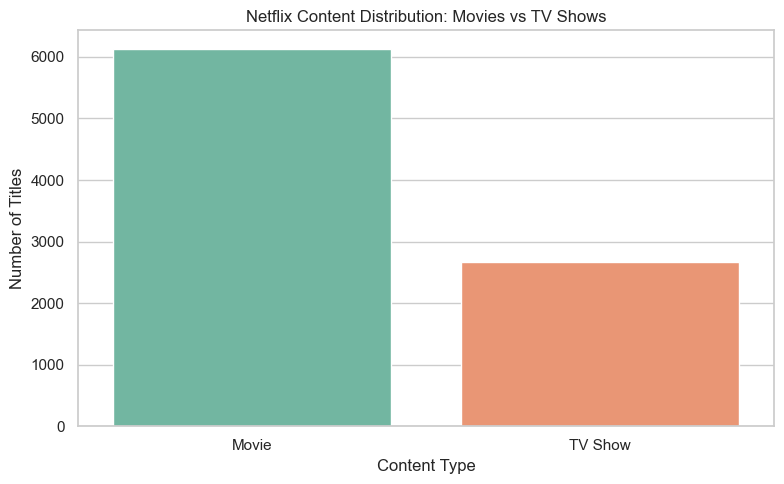

In [8]:
# Visualize content distribution by type

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="type",
    hue="type",
    palette="Set2",
    legend=False
)

plt.title("Netflix Content Distribution: Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

plt.tight_layout()
plt.show()

In [9]:
# Split multiple countries into individual entries
countries = df["country"].dropna().str.split(",")

# Convert each country into a separate row
countries = countries.explode()

# Remove extra spaces
countries = countries.str.strip()

# Exclude unavailable country information
countries = countries[countries != "Not Available"]

# Count titles by country
top_countries = countries.value_counts().head(10)

# Display top 10 countries
print("Top 10 Countries by Netflix Content:")
display(top_countries)

Top 10 Countries by Netflix Content:


country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64

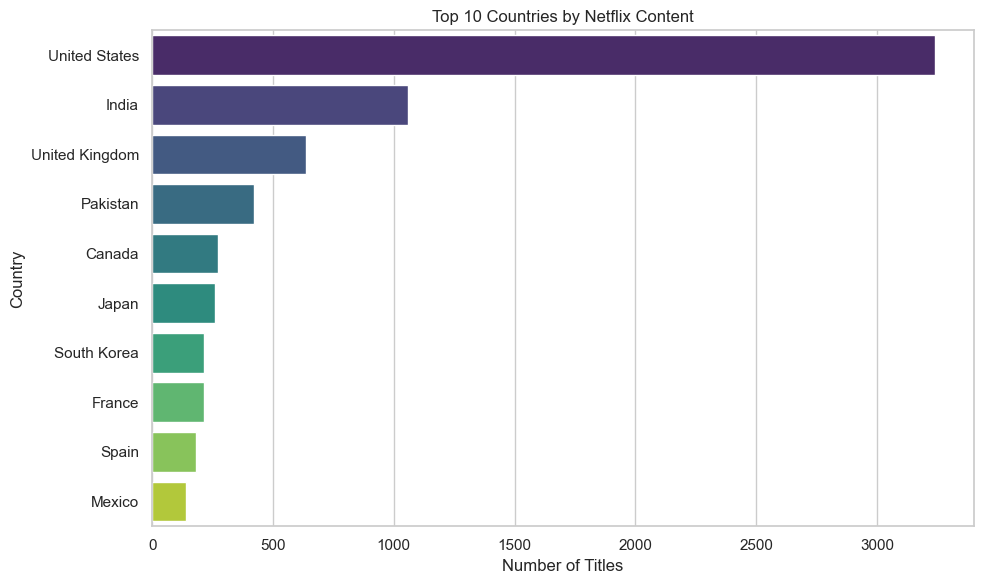

In [10]:
# Visualize the top 10 countries

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index,
    hue=top_countries.index,
    palette="viridis",
    legend=False
)

plt.title("Top 10 Countries by Netflix Content")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.tight_layout()

# Save visualization
plt.savefig(
    "../visualizations/top_10_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
# Split multiple categories into individual entries

categories = df["listed_in"].dropna().str.split(",")

# Convert each category into a separate row
categories = categories.explode()

# Remove unnecessary spaces
categories = categories.str.strip()

# Count the occurrences of each category
top_categories = categories.value_counts().head(10)

# Display the top 10 categories
print("Top 10 Netflix Content Categories:")
display(top_categories)

Top 10 Netflix Content Categories:


listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

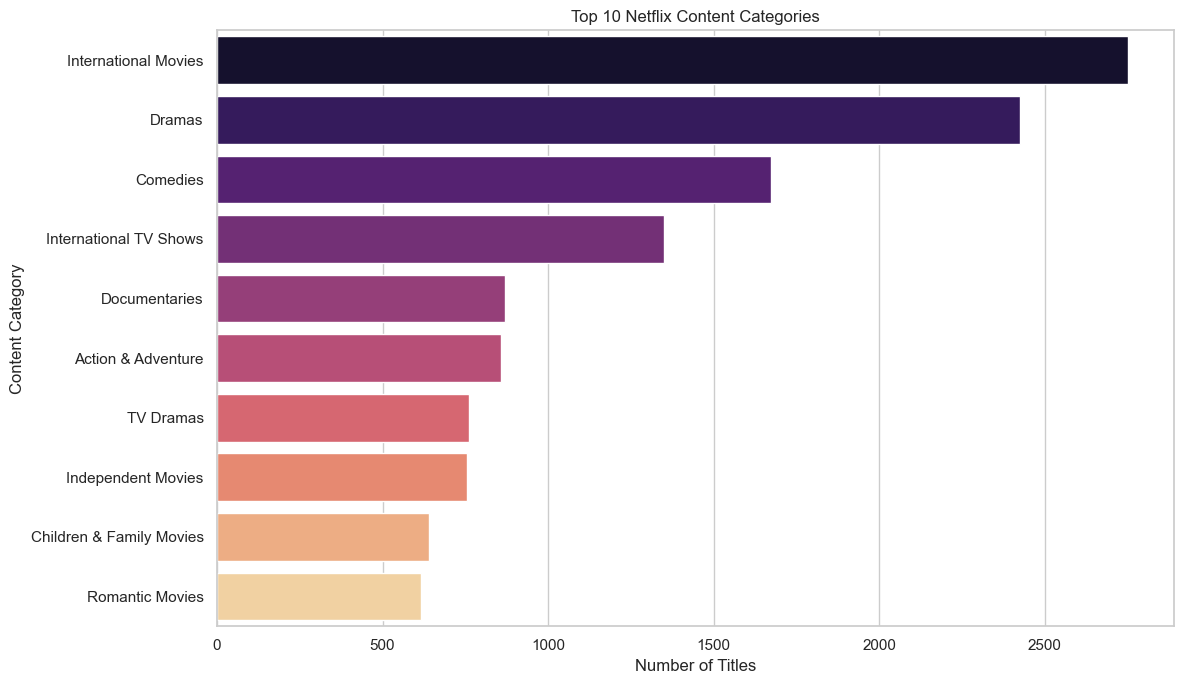

In [12]:
# Visualize the top 10 Netflix categories

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_categories.values,
    y=top_categories.index,
    hue=top_categories.index,
    palette="magma",
    legend=False
)

plt.title("Top 10 Netflix Content Categories")
plt.xlabel("Number of Titles")
plt.ylabel("Content Category")

plt.tight_layout()

# Save the chart
plt.savefig(
    "../visualizations/top_10_categories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
# Analyze the number of titles added each year

yearly_content = df["date_added_year"].value_counts().sort_index()

print("Netflix Content Added Per Year:")
display(yearly_content)

Netflix Content Added Per Year:


date_added_year
2008       2
2009       2
2010       1
2011      13
2012       3
2013      11
2014      24
2015      82
2016     426
2017    1185
2018    1648
2019    2016
2020    1879
2021    1498
Name: count, dtype: int64

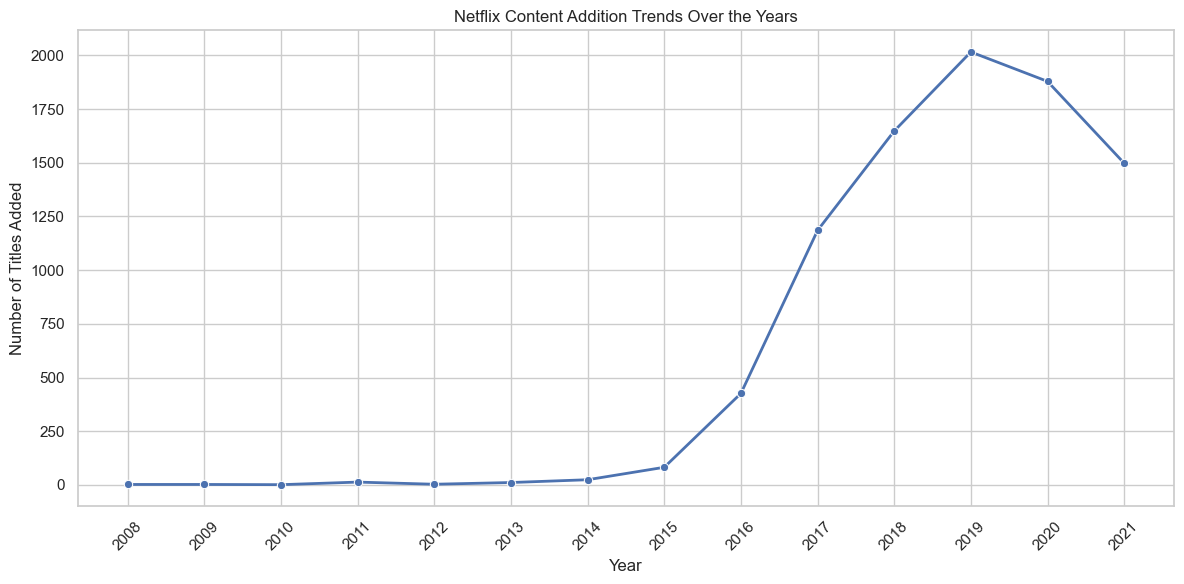

In [14]:
# Visualize Netflix content addition trends

plt.figure(figsize=(12, 6))

sns.lineplot(
    x=yearly_content.index,
    y=yearly_content.values,
    marker="o",
    linewidth=2
)

plt.title("Netflix Content Addition Trends Over the Years")
plt.xlabel("Year")
plt.ylabel("Number of Titles Added")
plt.xticks(yearly_content.index, rotation=45)

plt.tight_layout()

# Save visualization
plt.savefig(
    "../visualizations/yearly_content_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
# Separate Movies and TV Shows

movies = df[df["type"] == "Movie"]
tv_shows = df[df["type"] == "TV Show"]

# Calculate average movie duration
average_movie_duration = movies["duration_value"].mean()

# Calculate average TV show seasons
average_tv_seasons = tv_shows["duration_value"].mean()

print("MOVIE ANALYSIS")
print("Total Movies:", len(movies))
print("Average Movie Duration:", round(average_movie_duration, 2), "minutes")

print("\nTV SHOW ANALYSIS")
print("Total TV Shows:", len(tv_shows))
print("Average TV Show Seasons:", round(average_tv_seasons, 2))

MOVIE ANALYSIS
Total Movies: 6126
Average Movie Duration: 99.58 minutes

TV SHOW ANALYSIS
Total TV Shows: 2664
Average TV Show Seasons: 1.75


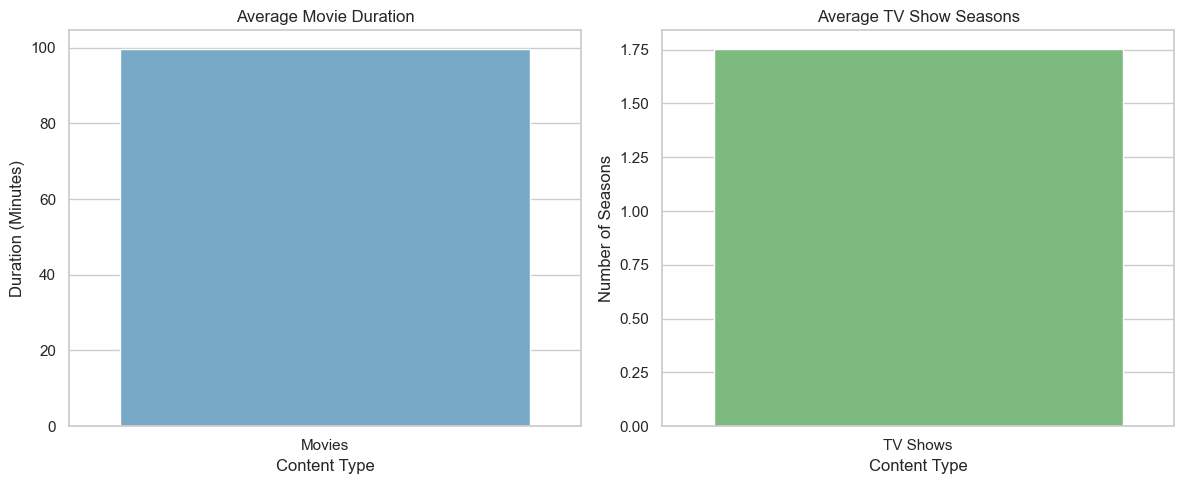

In [16]:
# Create two separate visualizations

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Average movie duration
sns.barplot(
    x=["Movies"],
    y=[average_movie_duration],
    hue=["Movies"],
    palette="Blues",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Average Movie Duration")
axes[0].set_ylabel("Duration (Minutes)")
axes[0].set_xlabel("Content Type")

# Average TV show seasons
sns.barplot(
    x=["TV Shows"],
    y=[average_tv_seasons],
    hue=["TV Shows"],
    palette="Greens",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Average TV Show Seasons")
axes[1].set_ylabel("Number of Seasons")
axes[1].set_xlabel("Content Type")

plt.tight_layout()

# Save visualization
plt.savefig(
    "../visualizations/average_duration_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
# Analyze content by original release year

release_year_counts = df["release_year"].value_counts().sort_index()

# Display the most recent 10 release years by title count
top_release_years = df["release_year"].value_counts().head(10)

print("Top 10 Release Years by Number of Titles:")
display(top_release_years)

print("\nRelease Year Statistics:")
print("Oldest Release Year:", df["release_year"].min())
print("Latest Release Year:", df["release_year"].max())
print("Average Release Year:", round(df["release_year"].mean(), 2))

Top 10 Release Years by Number of Titles:


release_year
2018    1146
2019    1030
2017    1030
2020     953
2016     901
2021     592
2015     555
2014     352
2013     286
2012     236
Name: count, dtype: int64


Release Year Statistics:
Oldest Release Year: 1925
Latest Release Year: 2021
Average Release Year: 2014.18


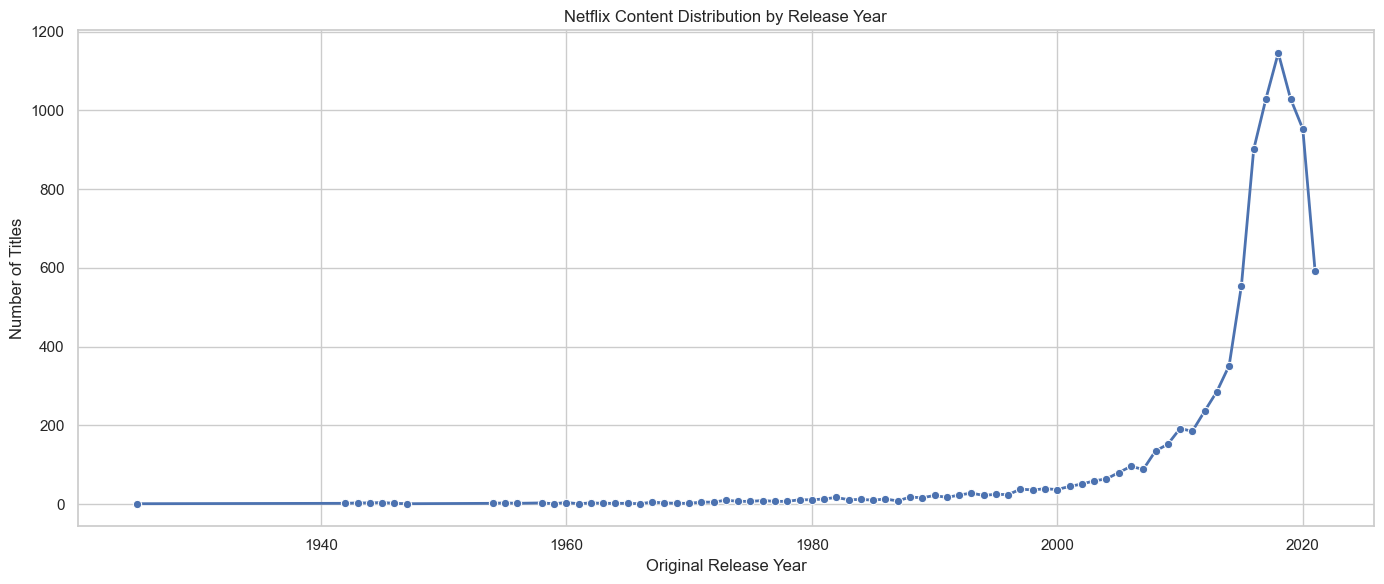

In [18]:
# Visualize Netflix titles by original release year

plt.figure(figsize=(14, 6))

sns.lineplot(
    x=release_year_counts.index,
    y=release_year_counts.values,
    marker="o",
    linewidth=2
)

plt.title("Netflix Content Distribution by Release Year")
plt.xlabel("Original Release Year")
plt.ylabel("Number of Titles")

plt.tight_layout()

# Save visualization
plt.savefig(
    "../visualizations/release_year_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
# Analyze Netflix content ratings

rating_counts = df["rating"].value_counts()

print("Netflix Content Rating Distribution:")
display(rating_counts)

# Identify the top 10 ratings
top_ratings = rating_counts.head(10)

print("\nTop 10 Content Ratings:")
display(top_ratings)

Netflix Content Rating Distribution:


rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


Top 10 Content Ratings:


rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
TV-Y7     333
TV-Y      306
PG        287
TV-G      220
NR         79
Name: count, dtype: int64

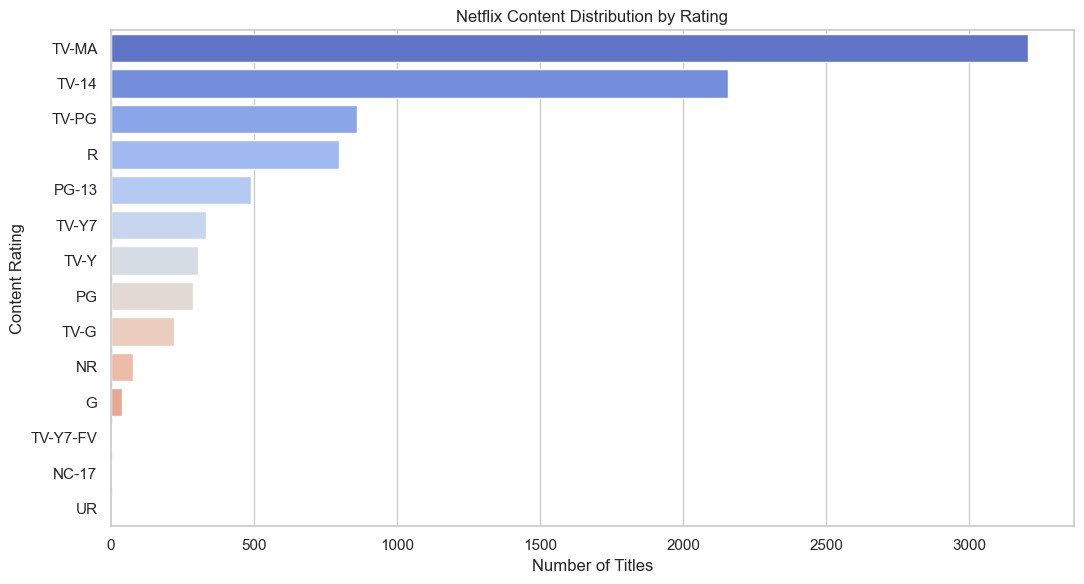

In [20]:
# Visualize Netflix content ratings

plt.figure(figsize=(11, 6))

sns.barplot(
    x=rating_counts.values,
    y=rating_counts.index,
    hue=rating_counts.index,
    palette="coolwarm",
    legend=False
)

plt.title("Netflix Content Distribution by Rating")
plt.xlabel("Number of Titles")
plt.ylabel("Content Rating")

plt.tight_layout()

# Save visualization
plt.savefig(
    "../visualizations/content_rating_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
# Analyze Netflix content additions by month

monthly_content = (
    df["date_added_month_name"]
    .value_counts()
    .reindex([
        "January", "February", "March", "April",
        "May", "June", "July", "August",
        "September", "October", "November", "December"
    ])
)

print("Netflix Content Added by Month:")
display(monthly_content)

Netflix Content Added by Month:


date_added_month_name
January      737
February     562
March        741
April        763
May          632
June         728
July         827
August       754
September    769
October      760
November     705
December     812
Name: count, dtype: int64

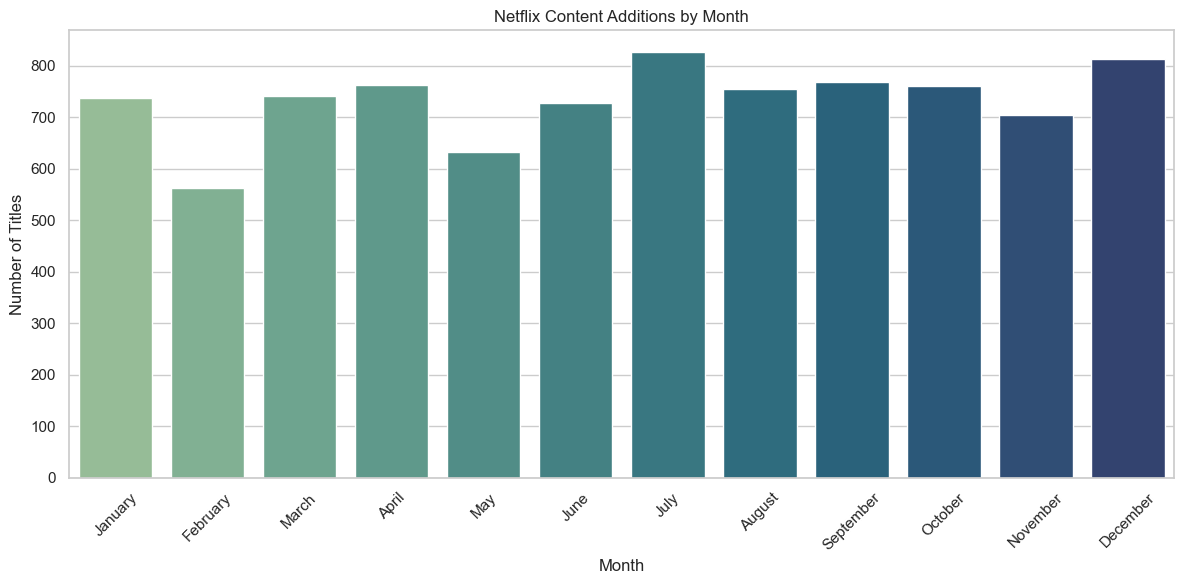

In [22]:
# Visualize Netflix content additions by month

plt.figure(figsize=(12, 6))

sns.barplot(
    x=monthly_content.index,
    y=monthly_content.values,
    hue=monthly_content.index,
    palette="crest",
    legend=False
)

plt.title("Netflix Content Additions by Month")
plt.xlabel("Month")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.tight_layout()

# Save visualization
plt.savefig(
    "../visualizations/monthly_content_additions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
# Final Data Quality Verification

print("DATASET SHAPE")
print(df.shape)

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nTOTAL MISSING VALUES")
print(df.isnull().sum().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nCONTENT TYPE DISTRIBUTION")
display(df["type"].value_counts())

DATASET SHAPE
(8790, 15)

MISSING VALUES
show_id                  0
type                     0
title                    0
director                 0
country                  0
date_added               0
release_year             0
rating                   0
duration                 0
listed_in                0
duration_value           0
duration_unit            0
date_added_year          0
date_added_month         0
date_added_month_name    0
dtype: int64

TOTAL MISSING VALUES
0

DUPLICATE ROWS
0

CONTENT TYPE DISTRIBUTION


type
Movie      6126
TV Show    2664
Name: count, dtype: int64